In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model

# Load MNIST dataset
(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()

# Normalize images between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images: 28 x 28 = 784
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 784)
Testing data: (10000, 784)


In [2]:

# Encoder
input_img = layers.Input(shape=(784,))
encoded = layers.Dense(256, activation="relu")(input_img)
encoded = layers.Dense(128, activation="relu")(encoded)
latent = layers.Dense(32, activation="relu")(encoded)

# Decoder
decoded = layers.Dense(128, activation="relu")(latent)
decoded = layers.Dense(256, activation="relu")(decoded)
output_img = layers.Dense(784, activation="sigmoid")(decoded)

# Autoencoder model
autoencoder = Model(input_img, output_img)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()

# Train model
history_ae = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       201,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 476,720 (1.82 MB)

 Trainable params: 476,720 (1.82 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - loss: 0.2154 - val_loss: 0.1404
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - loss: 0.1286 - val_loss: 0.1180
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - loss: 0.1136 - val_loss: 0.1076
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - loss: 0.1056 - val_loss: 0.1013
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.1008 - val_loss: 0.0978
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0974 - val_loss: 0.0955
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0951 - val_loss: 0.0931
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - loss: 0.0932 - val_loss: 0.0914
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0917 - val_loss: 0.0905
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.0904 - val_loss: 0.0891


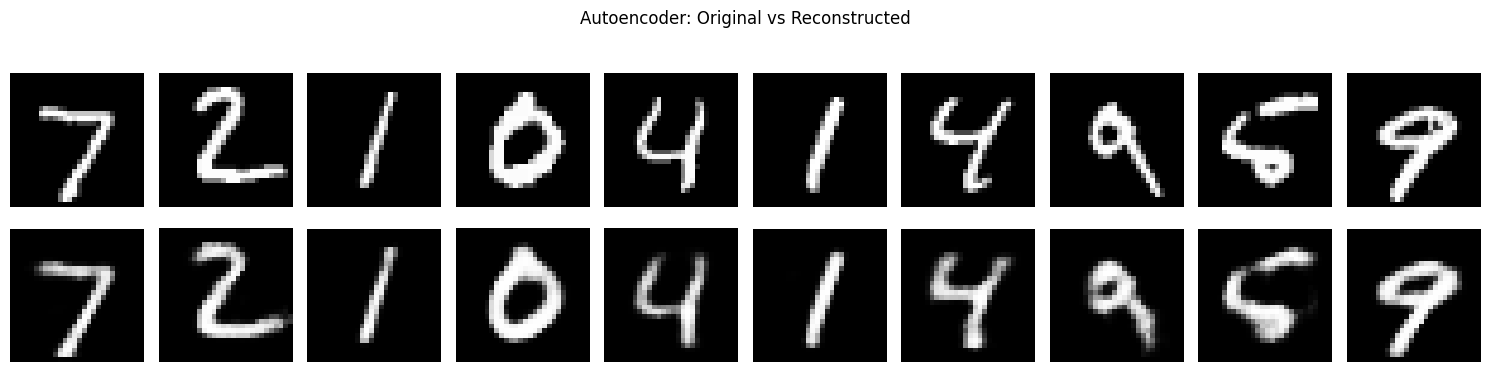

In [3]:

# Reconstruct test images
ae_reconstructed = autoencoder.predict(x_test[:10], verbose=0)

plt.figure(figsize=(15, 4))

for i in range(10):
    # Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    # Reconstructed images
    plt.subplot(2, 10, i + 11)
    plt.imshow(ae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.suptitle("Autoencoder: Original vs Reconstructed")
plt.tight_layout()
plt.show()


In [4]:

LATENT_DIM = 32

# Sampling layer: reparameterization trick
class Sampling(layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * epsilon

# VAE encoder
vae_input = layers.Input(shape=(784,))
h = layers.Dense(256, activation="relu")(vae_input)
h = layers.Dense(128, activation="relu")(h)

z_mean = layers.Dense(LATENT_DIM, name="z_mean")(h)
z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(h)
z = Sampling()([z_mean, z_log_var])

encoder = Model(
    vae_input, [z_mean, z_log_var, z],
    name="encoder"
)

# VAE decoder
latent_input = layers.Input(shape=(LATENT_DIM,))
h = layers.Dense(128, activation="relu")(latent_input)
h = layers.Dense(256, activation="relu")(h)
vae_output = layers.Dense(784, activation="sigmoid")(h)

decoder = Model(latent_input, vae_output, name="decoder")

# VAE model with combined loss
class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = tf.keras.metrics.Mean(
            name="loss"
        )
        self.reconstruction_tracker = tf.keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_tracker,
            self.kl_tracker
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            # Sum pixel-wise reconstruction loss
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.backend.binary_crossentropy(
                        data, reconstruction
                    ),
                    axis=1
                )
            )

            # KL divergence
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean)
                    - tf.exp(log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss, self.trainable_weights
        )
        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_tracker.update_state(
            reconstruction_loss
        )
        self.kl_tracker.update_state(kl_loss)

        return {m.name: m.result() for m in self.metrics}

    def call(self, inputs):
        mean, log_var, z = self.encoder(inputs)
        return self.decoder(z)

vae = VAE(encoder, decoder)
vae.compile(optimizer="adam")

# Train the VAE
history_vae = vae.fit(
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True
)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - kl_loss: 7.0786 - loss: 201.8514 - reconstruction_loss: 194.7729
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - kl_loss: 15.7562 - loss: 147.7128 - reconstruction_loss: 131.9565
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - kl_loss: 18.1766 - loss: 132.0654 - reconstruction_loss: 113.8888
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - kl_loss: 19.0197 - loss: 124.0248 - reconstruction_loss: 105.0051
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - kl_loss: 19.7350 - loss: 119.3142 - reconstruction_loss: 99.5792 
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - kl_loss: 20.3919 - loss: 116.0140 - reconstruction_loss: 95.6221
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - kl_loss: 20.9115 - loss: 113.7207 - reconstruction_loss: 92.8092
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - kl_loss: 21.2704 - loss: 111.8732 - reconstruction_loss: 90.6029
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━

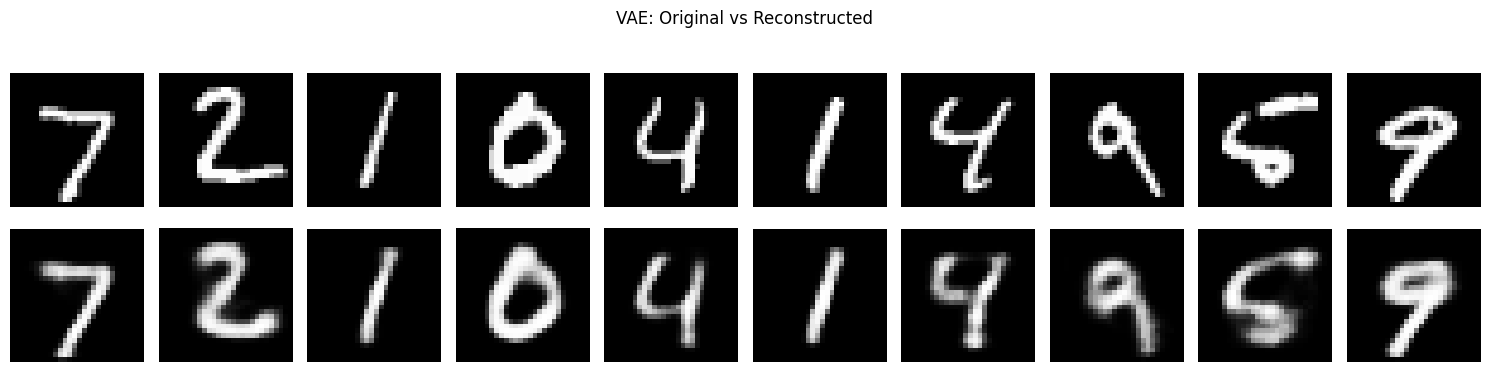

In [5]:

# Reconstruct test images
vae_reconstructed = vae.predict(x_test[:10], verbose=0)

plt.figure(figsize=(15, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(2, 10, i + 11)
    plt.imshow(vae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("VAE Reconstructed")

plt.suptitle("VAE: Original vs Reconstructed")
plt.tight_layout()
plt.show()


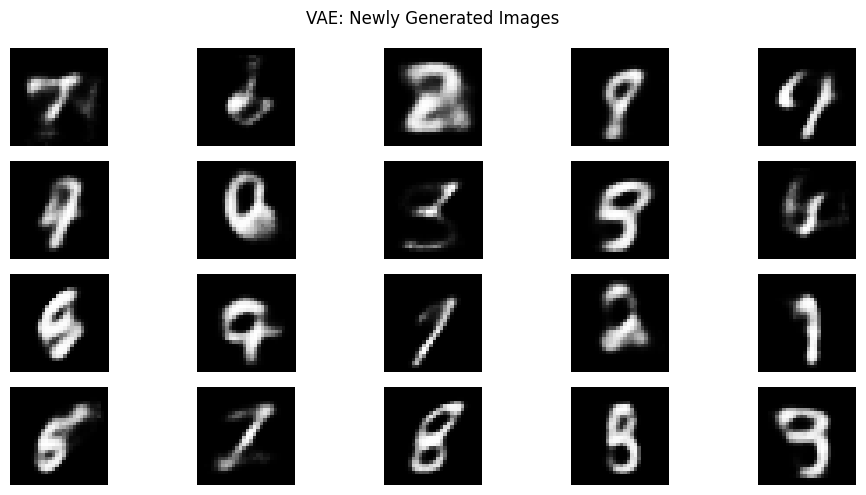

In [6]:

# Sample random vectors from a standard normal distribution
random_latent_vectors = tf.random.normal((20, LATENT_DIM))

# Generate images using the decoder
generated_images = decoder.predict(
    random_latent_vectors, verbose=0
)

plt.figure(figsize=(10, 5))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(
        generated_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("VAE: Newly Generated Images")
plt.tight_layout()
plt.show()


Autoencoder Test MSE: 0.009055
VAE Test MSE: 0.015972


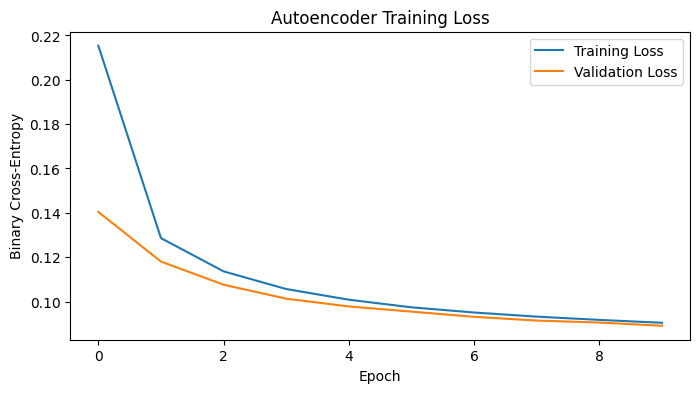

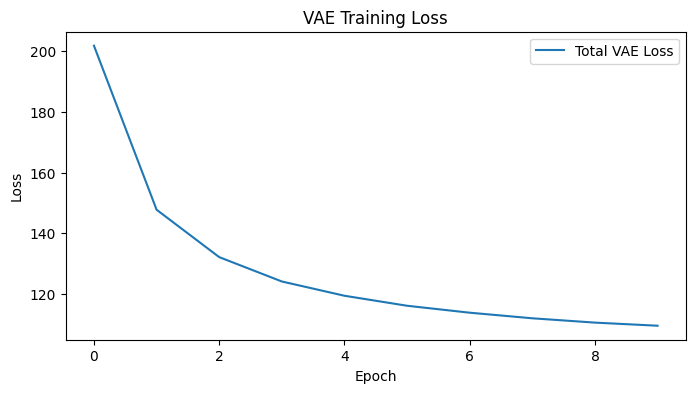

In [7]:

# Reconstruct all test images
ae_predictions = autoencoder.predict(x_test, verbose=0)
vae_predictions = vae.predict(x_test, verbose=0)

# Calculate reconstruction MSE
ae_mse = np.mean((x_test - ae_predictions) ** 2)
vae_mse = np.mean((x_test - vae_predictions) ** 2)

print("Autoencoder Test MSE:", round(float(ae_mse), 6))
print("VAE Test MSE:", round(float(vae_mse), 6))

# Plot training loss for the Autoencoder
plt.figure(figsize=(8, 4))
plt.plot(history_ae.history["loss"], label="Training Loss")
plt.plot(history_ae.history["val_loss"], label="Validation Loss")
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.legend()
plt.show()

# Plot VAE loss
plt.figure(figsize=(8, 4))
plt.plot(history_vae.history["loss"], label="Total VAE Loss")
plt.title("VAE Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
